# SEALS Hardware: Specs, Flow Diagram, Design Equations, and Mie Plots

**Source:** J. Adam, A. Mahjoubfar, E. D. Diebold, B. W. Buckley & **B. Jalali**,
"Spectrally encoded angular light scattering," *Optics Express* **21**(23), 28960 (2013).

**The idea:** a flow cytometer normally measures scattered light at only two angles.
SEALS shines a *rainbow* on the particle, with each wavelength arriving from a
different angle, and reads the scattered **spectrum** at one fixed detector. The
wavelength encodes the angle, so one spectrum gives the whole angular scattering
profile in a single shot. Swap the spectrum analyzer for a **time-stretch dispersive
Fourier transform** and it runs in real time. That's the same dispersion physics as
$H(f) = e^{j\pi Df^2}$ in this repo's phase retrieval.

| § | content | tools |
|---|---|---|
| 1 | hardware specs, with paper section references | table |
| 2 | system flow diagram | matplotlib |
| 3 | design equations: grating dispersion, Eq. (1) λ→y, Eq. (2) y→θ, resolution | **SymPy** |
| 4 | the wavelength-to-angle map vs. the paper's Fig. 2–3 ranges | `scarlett.physics` |
| 5 | a reconciliation: the "0.48 nm, 42 angles" numbers | arithmetic, honestly |
| 6 | Mie profiles of the paper's 7.32 µm and 9.94 µm beads | `scarlett.physics.mie_scattering` |
| 7 | equalization and the time-stretch readout budget | model |

**Everything below is model output.** No measured data is reproduced; ranges
"read from" the paper's figures are labeled as such.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent / "src"))
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
from IPython.display import display, Math
sp.init_printing()
from scarlett import physics as ph
from scarlett import seals_hardware as sh

# 1. Hardware specifications (as published)

In [2]:
print(f"{'item':32s} {'value':>10s}  {'unit / note':48s} source")
for item, val, unit, src in sh.PAPER_SPECS:
    v = f"{val:.4g}" if isinstance(val, (int, float)) else ""
    note = unit if v else f"{val} {unit}".strip()
    print(f"{item:32s} {v:>10s}  {note[:48]:48s} {src}")

item                                  value  unit / note                                      source
source                                       pulsed mode-locked laser, broadband, spatially c Sec. 2
center wavelength lam0                 1590  nm                                               Sec. 2
optical bandwidth                        20  nm (1.3 % fractional)                            Sec. 2
equalization                                 tunable optical filter + quarter/half-wave plate Sec. 2
grating pair                                 parallel, equal groove spacing, 1st order (m = 1 Sec. 3
grating pitch                          1100  as printed 'd = 1100 nm' (see reconciliation)    Sec. 3
telescope magnification M            0.1667                                                   Sec. 3
objective                                    60x, NA = 0.7                                    Sec. 2
entrance beam waist w0                    3  mm ('measures 3 mm')                          

# 2. Flow diagram

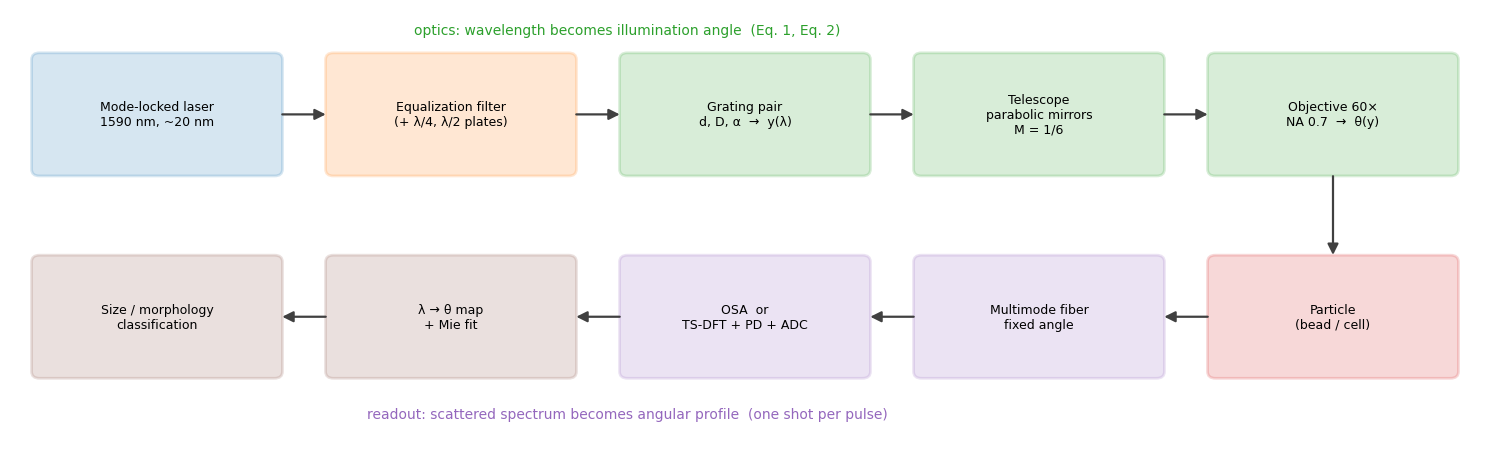

In [3]:
blocks = [("Mode-locked laser\n1590 nm, ~20 nm", "C0"), ("Equalization filter\n(+ λ/4, λ/2 plates)", "C1"),
          ("Grating pair\nd, D, α  →  y(λ)", "C2"), ("Telescope\nparabolic mirrors\nM = 1/6", "C2"),
          ("Objective 60×\nNA 0.7  →  θ(y)", "C2"), ("Particle\n(bead / cell)", "C3"),
          ("Multimode fiber\nfixed angle", "C4"), ("OSA  or\nTS-DFT + PD + ADC", "C4"),
          ("λ → θ map\n+ Mie fit", "C5"), ("Size / morphology\nclassification", "C5")]
fig, ax = plt.subplots(figsize=(15, 4.6)); ax.axis("off")
xs = [i % 5 * 3.0 for i in range(10)]; ys = [2.4 if i < 5 else 0 for i in range(10)]
xs[5:] = xs[5:][::-1]
for (txt, col), x, y in zip(blocks, xs, ys):
    ax.add_patch(FancyBboxPatch((x, y), 2.4, 1.3, boxstyle="round,pad=0.08", fc=col, alpha=0.18, ec=col, lw=2))
    ax.text(x + 1.2, y + 0.65, txt, ha="center", va="center", fontsize=9)
for i in range(9):
    x0, y0, x1, y1 = xs[i], ys[i], xs[i + 1], ys[i + 1]
    if y0 == y1:
        s, e = ((x0 + 2.45, y0 + .65), (x1 - .05, y1 + .65)) if x1 > x0 else ((x0 - .05, y0 + .65), (x1 + 2.45, y1 + .65))
    else:
        s, e = (x0 + 1.2, y0 - .05), (x1 + 1.2, y1 + 1.35)
    ax.add_patch(FancyArrowPatch(s, e, arrowstyle="-|>", mutation_scale=16, lw=1.6, color="0.25"))
ax.text(6.0, 4.0, "optics: wavelength becomes illumination angle  (Eq. 1, Eq. 2)", ha="center", color="C2", fontsize=10)
ax.text(6.0, -0.55, "readout: scattered spectrum becomes angular profile  (one shot per pulse)", ha="center", color="C4", fontsize=10)
ax.set_xlim(-0.3, 14.7); ax.set_ylim(-0.8, 4.3); plt.tight_layout(); plt.show()

# 3. Design equations in SymPy

**Grating equation (first order, $m = 1$):** $\sin\beta = m\lambda/d - \sin\alpha$. Its
derivative is the **angular dispersion**, which spreads the colors:

In [4]:
beta, disp, (lam, d, a, m) = sh.grating_symbolic()
display(Math(r"\beta(\lambda) = " + sp.latex(beta)))
display(Math(r"\frac{d\beta}{d\lambda} = " + sp.latex(disp) + r"\;=\; \frac{m}{d\cos\beta}"))
v = {lam: 1.59e-6, d: 9.0909e-7, a: 0.9023, m: 1}
print(f"at 1590 nm: β = {float(sp.deg(beta.subs(v))):.2f}°,  dβ/dλ = {float(disp.subs(v))*1e-9*180/np.pi:.4f} deg/nm")

<IPython.core.display.Math object>

<IPython.core.display.Math object>

at 1590 nm: β = 74.63°,  dβ/dλ = 0.2378 deg/nm


**Eq. (1): beam displacement** after the grating pair (separation $D$, telescope $M$):
$y = M\,\dfrac{D\tan(\alpha-\beta)}{1 + \tan(\alpha-\beta)\tan\alpha}$.

**Eq. (2): displacement to angle** through an objective with entrance pupil $P$:
$\theta = \tan^{-1}\!\big(\tfrac2P\,(y - y_c + d_\text{corr})\tan(\sin^{-1}\mathrm{NA})\big)$. Its slope at the
beam center sets how many degrees each millimeter of rainbow becomes:

In [5]:
th, slope, (y, yc, dc, P, NA) = sh.angle_symbolic()
display(Math(r"\left.\frac{d\theta}{dy}\right|_\text{center} = " + sp.latex(slope)))
print(f"NA = 0.7, P = 5.8 mm  →  {float(slope.subs({NA: 0.7, P: 5.8e-3}))*1e-3*180/np.pi:.1f} deg per mm of displacement")
f, (ap, L) = sh.min_resolvable_angle_symbolic()
display(Math(r"\Delta\theta_\min = " + sp.latex(f) + r"\quad(\text{detector aperture } a \text{ at distance } L)"))

<IPython.core.display.Math object>

NA = 0.7, P = 5.8 mm  →  19.4 deg per mm of displacement


<IPython.core.display.Math object>

# 4. The wavelength-to-angle map

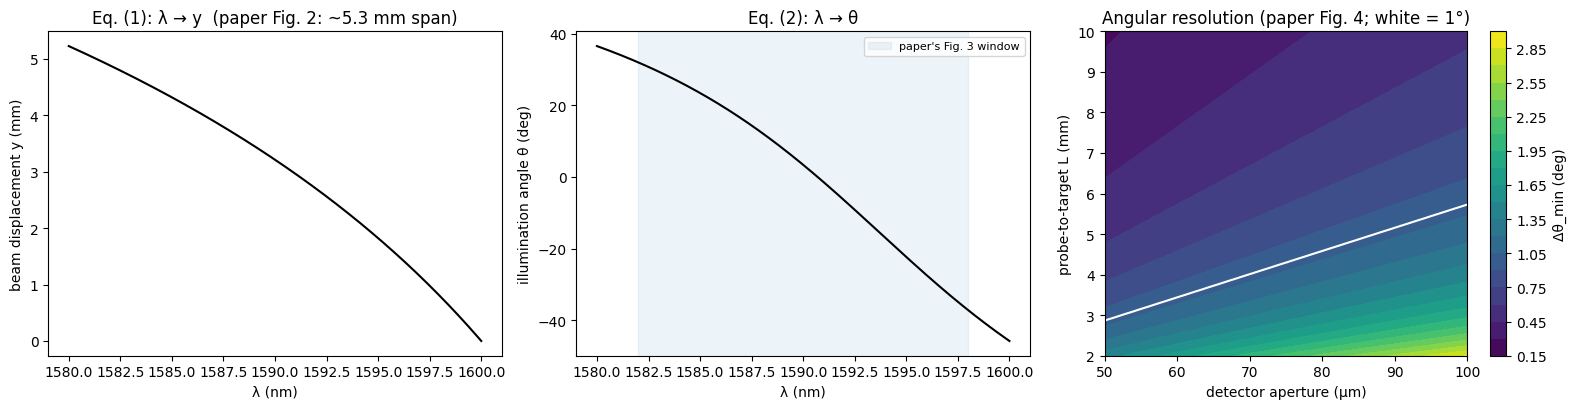

y span 1580→1600 nm: 5.23 mm   (paper Fig. 2 ≈ 5.3 mm)
θ over 1582→1598 nm: +32.0° → -37.2°, span 69.1°   (read from paper Fig. 3: ≈ +41° → −27°, span ≈ 68°)


In [6]:
lamv, yv, thv = sh.mapping()
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
axes[0].plot(lamv*1e9, yv*1e3, "k"); axes[0].set(xlabel="λ (nm)", ylabel="beam displacement y (mm)", title="Eq. (1): λ → y  (paper Fig. 2: ~5.3 mm span)")
axes[1].plot(lamv*1e9, np.degrees(thv), "k"); axes[1].axvspan(1582, 1598, color="C0", alpha=0.08, label="paper's Fig. 3 window")
axes[1].set(xlabel="λ (nm)", ylabel="illumination angle θ (deg)", title="Eq. (2): λ → θ"); axes[1].legend(fontsize=8)
aa = np.linspace(50e-6, 100e-6, 60); LL = np.linspace(2e-3, 10e-3, 60); A, LLg = np.meshgrid(aa, LL)
cs = axes[2].contourf(A*1e6, LLg*1e3, np.degrees(ph.seals_min_resolvable_angle(A, LLg)), 20, cmap="viridis")
axes[2].contour(A*1e6, LLg*1e3, np.degrees(ph.seals_min_resolvable_angle(A, LLg)), [1.0], colors="w")
plt.colorbar(cs, ax=axes[2], label="Δθ_min (deg)")
axes[2].set(xlabel="detector aperture (µm)", ylabel="probe-to-target L (mm)", title="Angular resolution (paper Fig. 4; white = 1°)")
plt.tight_layout(); plt.show()
i1, i2 = np.argmin(abs(lamv - 1582e-9)), np.argmin(abs(lamv - 1598e-9))
print(f"y span 1580→1600 nm: {yv[0]*1e3:.2f} mm   (paper Fig. 2 ≈ 5.3 mm)")
print(f"θ over 1582→1598 nm: {np.degrees(thv[i1]):+.1f}° → {np.degrees(thv[i2]):+.1f}°, span {np.degrees(thv[i1]-thv[i2]):.1f}°   "
      f"(read from paper Fig. 3: ≈ +41° → −27°, span ≈ 68°)")

The **span** agrees (69° vs. about 68°), but the curve is shifted by about 9°. The paper
says $P$ and $d_\text{corr}$ were *fitted* to the measurement, and the parameter set used
here (the lab simulation's defaults) is evidently a different fit. A shift in
$d_\text{corr}$ moves the whole curve without changing its span, exactly as seen here.

# 5. Reconciling "0.48 nm → 42 resolvable angles"

The paper uses $d\lambda = \lambda_0\,d/(2 m w_0)$ with "$d = 1100$ nm" and a beam waist
that "measures 3 mm", and reports 0.48 nm. Evaluate every reasonable reading:

In [7]:
print(f"{'reading':46s} {'dλ (nm)':>8s} {'angles in 20 nm':>16s}")
for label, dl, n in sh.resolution_reconciliation():
    mark = "  ← matches the paper" if abs(dl*1e9 - 0.48) < 0.01 else ""
    print(f"{label:46s} {dl*1e9:8.3f} {n:16.1f}{mark}")

reading                                         dλ (nm)  angles in 20 nm
as printed: d = 1100 nm, w0 = 3 mm                0.292             68.6
1100 lines/mm (d = 909 nm), w0 = 3 mm             0.241             83.0
d = 1100 nm, 3 mm = diameter (w0 = 1.5 mm)        0.583             34.3
1100 lines/mm AND 3 mm = diameter                 0.482             41.5  ← matches the paper


Only one reading reproduces the paper's own 0.48 nm and 42 angles. The grating is
**1100 lines/mm** (pitch 909 nm, which is the value the simulation uses), and "3 mm" is
the beam **diameter** ($w_0 = 1.5$ mm). This kind of check is worth doing on any paper
before you build hardware from it, and it would make a good, polite question for the lab.

# 6. Mie scattering of the paper's beads

Polystyrene beads, 7.32 µm and 9.94 µm, with $n = 1.39$ as the paper states, in air,
at λ = 1590 nm. Size parameters $x = \pi D/\lambda \approx 14.5$ and $19.6$. Mie
profiles from `scarlett.physics.mie_scattering` (the tested port):

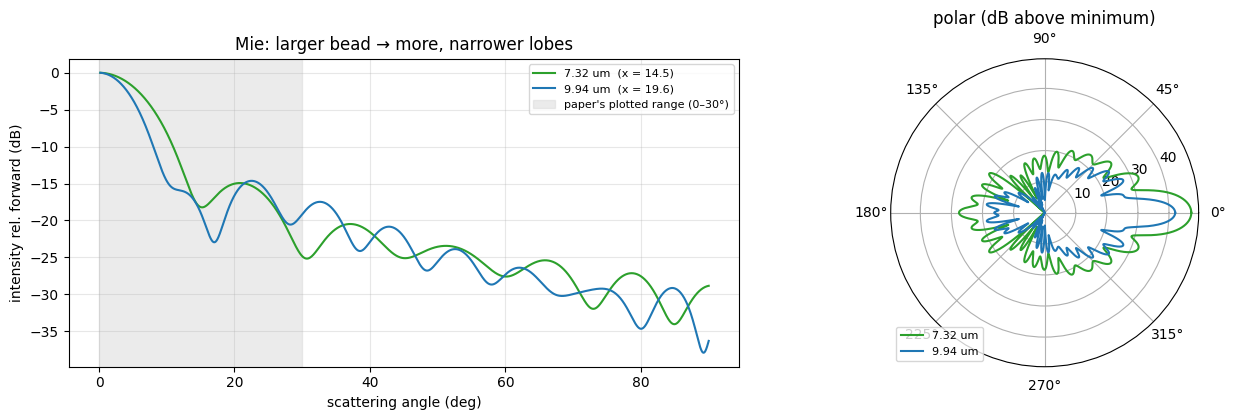

7.32 um: lobe period ≈ 180°/x = 12.4°;  maxima in 0–30°: 1,  20–50°: 2,  0–90°: 5


9.94 um: lobe period ≈ 180°/x = 9.2°;  maxima in 0–30°: 1,  20–50°: 3,  0–90°: 7


In [8]:
ang = np.radians(np.linspace(0.2, 90, 3000))
fig, axes = plt.subplots(1, 2, figsize=(14, 4.3))
for (name, dia), col in zip(sh.BEADS.items(), ("C2", "C0")):
    I = sh.bead_profile(dia, ang)
    axes[0].plot(np.degrees(ang), 10*np.log10(I/I[0]), col, label=f"{name}  (x = {float(ph.size_parameter(dia, sh.LAM0)):.1f})")
axes[0].axvspan(0, 30, color="0.85", alpha=0.5, label="paper's plotted range (0–30°)")
axes[0].set(xlabel="scattering angle (deg)", ylabel="intensity rel. forward (dB)", title="Mie: larger bead → more, narrower lobes")
axes[0].legend(fontsize=8); axes[0].grid(alpha=0.3)
pa = np.linspace(0, 2*np.pi, 2000)
axes[1].remove(); ax2 = fig.add_subplot(1, 2, 2, projection="polar")
for (name, dia), col in zip(sh.BEADS.items(), ("C2", "C0")):
    th_full = np.abs(np.arctan2(np.sin(pa), np.cos(pa))) + 1e-4
    I = sh.bead_profile(dia, th_full); ax2.plot(pa, 10*np.log10(I/I.min()), col, label=name)
ax2.set_title("polar (dB above minimum)"); ax2.legend(fontsize=8, loc="lower left")
plt.tight_layout(); plt.show()
for name, dia in sh.BEADS.items():
    print(f"{name}: lobe period ≈ 180°/x = {sh.lobe_period_deg(dia):.1f}°;  maxima in 0–30°: {sh.lobe_count(dia, 0.2, 30)},"
          f"  20–50°: {sh.lobe_count(dia, 20, 50)},  0–90°: {sh.lobe_count(dia, 0.2, 90)}")

**What matches, and what doesn't.** The model reproduces the paper's key claim: the
**larger bead has more lobes** (7 vs. 5 over 0–90°), because the lobe period scales as
$180°/x$. Over 0–30° alone, though, the model shows fewer lobes than the measured
Fig. 5 traces. Plausible reasons, none of them settled here:

- the paper's "Angle" axis may be measured relative to the fixed detection angle (the lab simulation adds a 20° offset);
- the beads were dried on glass, not isolated in air;
- $n = 1.39$ is lower than the usual ~1.57 for polystyrene;
- each wavelength sees a different illumination angle *and* a slightly different λ.

These are good questions to bring to a lab meeting, not things to paper over.

# 7. Equalization and the time-stretch readout

**Why equalize?** Forward scattering is far brighter than side scattering, so one
detector would need a huge dynamic range. SEALS pre-shapes the source spectrum so
that wavelengths headed to *weak* angles get *more* power. Because wavelength ↔ angle,
a simple spectral filter does it. (Detector fixed 20° off axis; model, ideal inverse
filter vs. a 10 dB-limited one.)

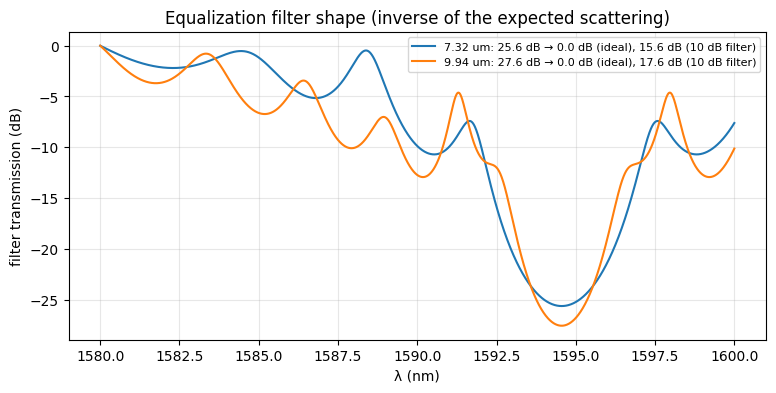

TS-DFT budget (assumed dispersion values):
    100 ps/nm × 20 nm →   2.0 ns record → ≥ 42.00 GS/s to sample 42 angles
    500 ps/nm × 20 nm →  10.0 ns record → ≥  8.40 GS/s to sample 42 angles
   1000 ps/nm × 20 nm →  20.0 ns record → ≥  4.20 GS/s to sample 42 angles
   2000 ps/nm × 20 nm →  40.0 ns record → ≥  2.10 GS/s to sample 42 angles


In [9]:
fig, ax = plt.subplots(figsize=(9, 4))
for name, dia in sh.BEADS.items():
    lamv, T, b, a = sh.equalization_filter(dia)
    _, _, b10, a10 = sh.equalization_filter(dia, max_atten_db=10)
    ax.plot(lamv*1e9, 10*np.log10(T), label=f"{name}: {b:.1f} dB → {a:.1f} dB (ideal), {a10:.1f} dB (10 dB filter)")
ax.set(xlabel="λ (nm)", ylabel="filter transmission (dB)", title="Equalization filter shape (inverse of the expected scattering)")
ax.legend(fontsize=8); ax.grid(alpha=0.3); plt.show()
print("TS-DFT budget (assumed dispersion values):")
for Dps in (100, 500, 1000, 2000):
    rec = sh.time_stretch_window(Dps)
    print(f"  {Dps:5d} ps/nm × 20 nm → {rec:5.1f} ns record → ≥ {sh.digitizer_rate_needed(42, rec)/1e9:5.2f} GS/s to sample 42 angles")

**Time-stretch link.** The dispersive fiber maps wavelength to time ($t = D\,\Delta\lambda$),
which is exactly the quadratic spectral phase $H(f) = e^{j\pi Df^2}$ this repo inverts
with Gerchberg–Saxton. With about 1000 ps/nm the 20 nm rainbow spreads over 20 ns,
and a 4 GS/s digitizer resolves all 42 angles: one angular profile per laser pulse,
with no spectrum analyzer.

## Exercises
1. Fit $d_\text{corr}$ so that θ(1590 nm) matches the paper's Fig. 3. Does the span stay the same?
2. Recompute §6 with $n = 1.57$ (typical polystyrene). Do the lobe counts in 0–30° move toward Fig. 5?
3. Add the 20° measurement-angle offset to §6's angle axis and re-count lobes.
4. Write the polite question you'd ask the lab about §5 and §6, with the numbers.